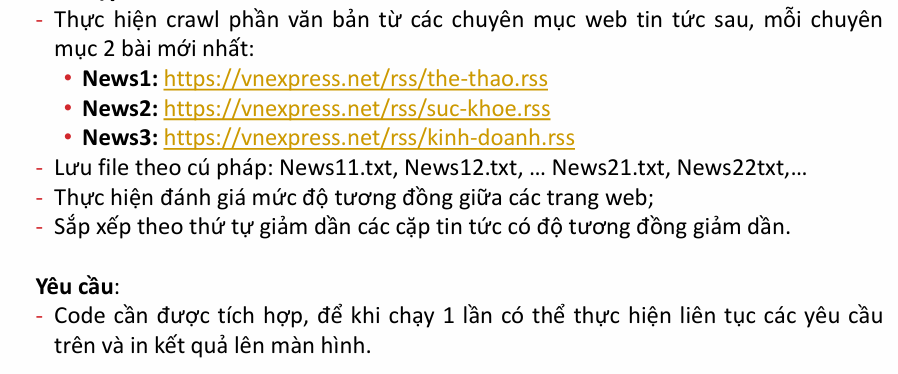

In [ ]:
import requests
import re
import unicodedata
import emot
import underthesea
from bs4 import BeautifulSoup

In [ ]:
url_list = ['https://vnexpress.net/rss/the-thao.rss',
            'https://vnexpress.net/rss/suc-khoe.rss',
            'https://vnexpress.net/rss/kinh-doanh.rss'
            ]

In [ ]:
emot_obj = emot.core.emot()

with open('vietnamese-stopwords.txt', 'r', encoding='utf-8') as f:
    stop_words = set(f.read().split('\n'))

In [ ]:
def get_content(soup):
    divs = soup.select('div.section-inner')[1:] # leave out the header
    if divs:
        return ' '.join(d.get_text(' ', strip=True) for d in divs)

    # p=normal and 
    parts = []
    title = soup.select_one('h1.title-detail')
    if title:
        parts.append(title.get_text(' ', strip=True))

    desc = soup.select_one('p.description')
    if desc:
        parts.append(desc.get_text(' ', strip=True))

    parts += [p.get_text(' ', strip=True) for p in soup.select('article.fck_detail p.Normal')]

    return ' '.join(parts)

In [ ]:
def preprocess(text):
    
    # lowercase
    text = text.lower()

    text = unicodedata.normalize("NFC", text)

    # remove_url
    text = re.sub(r'https?://\S+', '', text, flags=re.IGNORECASE)
    text = re.sub(r'www\.\S+', '', text, flags=re.IGNORECASE)

    # convert emoji
    emoji = emot_obj.emoji(text)
    for value, mean in zip(emoji['value'], emoji['mean']):
        text = text.replace(value, mean.replace(':', ' '))

    emoticons = emot_obj.emoticons(text)
    for value, mean in zip(emoticons['value'], emoticons['mean']):
        text = text.replace(value, '_'.join(mean.split()))

    # remove punctuation
    text = re.sub(r'[^\w\s]*', '', text)

    # remove digits
    text = re.sub(r'\d+', '', text)

    # correct spelling
    text = underthesea.text_normalize(text)

    # remove stop words
    text = ' '.join(w for w in text.split() if w not in stop_words)

    # word tokenize
    tokens = underthesea.word_tokenize(text)

    # return a sentence with tokenized word
    return ' '.join(tokens)

In [ ]:
url_count = 0

for url in url_list:
    
    r = requests.get(url)
    if r.status_code == 200:
        url_count += 1
        news_count = 0
        soup = BeautifulSoup(r.text, 'xml') # use xml for rss page
        items = soup.find_all('item')[:2]
        for item in items:
            news_url = item.find('link').text
            
            news_r = requests.get(news_url)
            if news_r.status_code == 200:
                news_count += 1
                content = get_content(BeautifulSoup(news_r.text))
                preprocessed_text = preprocess(content)
                print(preprocessed_text)
                with open(f'News{url_count}{news_count}.txt', mode='w', encoding='utf-8') as f:
                    f.write(preprocessed_text)
                print(f'Done with news {news_url}')
        print(f'Done with {url}')
    else:
        print(f'Không gửi được requests tới: {url}')

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

names = ['News11', 'News12', 'News21', 'News22', 'News31', 'News32']
docs = {}
for name in names:
    with open(f'{name}.txt', encoding='utf-8') as f:
        docs[name] = f.read()
print(docs)

# bow vector
vectorizer = CountVectorizer(token_pattern=r'\S+')
bow = vectorizer.fit_transform(docs.values())

# 3. Ma trận cosine similarity
sim_df = pd.DataFrame(cosine_similarity(bow), index=docs.keys(), columns=docs.keys())
display(sim_df)